100%|██████████| 41.0M/41.0M [00:00<00:00, 83.9MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/clmentbisaillon/fake-and-real-news-dataset/versions/1


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Accuracy: 83.53 %


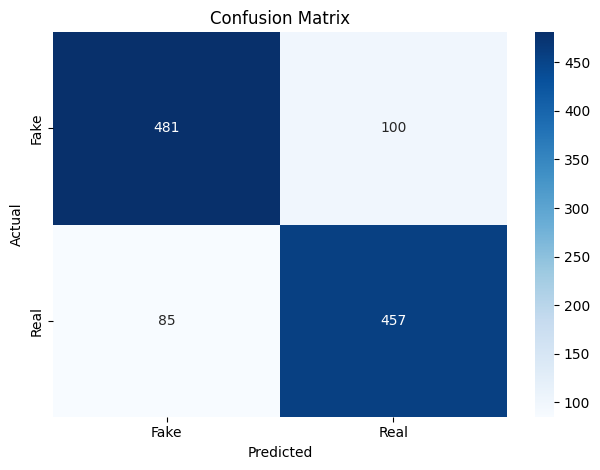


Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.83      0.84       581
           1       0.82      0.84      0.83       542

    accuracy                           0.84      1123
   macro avg       0.84      0.84      0.84      1123
weighted avg       0.84      0.84      0.84      1123



In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

path = kagglehub.dataset_download("clmentbisaillon/fake-and-real-news-dataset")
print("Path to dataset files:", path)

fake = pd.read_csv(f"{path}/Fake.csv")
true = pd.read_csv(f"{path}/True.csv")

fake["label"] = 0
true["label"] = 1

data = pd.concat([fake, true], axis=0)

# Very small sample to drastically limit training data
data = data.sample(frac=0.05, random_state=42).reset_index(drop=True)

data = data.sample(frac=1, random_state=42)

X = data["text"]
y = data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42   # more test, less train
)

# Very few features = weak signal
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.7,             # more aggressive filtering
    min_df=3,               # ignore rare words
    max_features=30         # only 30 features
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Aggressive underfitting
model = PassiveAggressiveClassifier(max_iter=1, C=0.0001)  # very low C = weak model

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

score = accuracy_score(y_test, y_pred)
print("Accuracy:", round(score * 100, 2), "%")

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fake", "Real"],
            yticklabels=["Fake", "Real"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nClassification Report:\n", classification_report(y_test, y_pred))

100%|██████████| 41.0M/41.0M [00:00<00:00, 59.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/clmentbisaillon/fake-and-real-news-dataset/versions/1

          DATASET INFORMATION

Fake News Articles: 23481
Real News Articles: 21417
Total Articles: 44898

Fake Dataset Shape: (23481, 4)
Real Dataset Shape: (21417, 4)

             COLUMN NAMES

Fake Columns:
['title', 'text', 'subject', 'date']

Real Columns:
['title', 'text', 'subject', 'date']

             SAMPLE DATA

Fake News:
                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text subject  \
0  Donald Trump just couldn t wish all Americans ...    News   
1  House Intelligence Committee Chairman Devin Nu...    News   
2  On Friday, it was rev

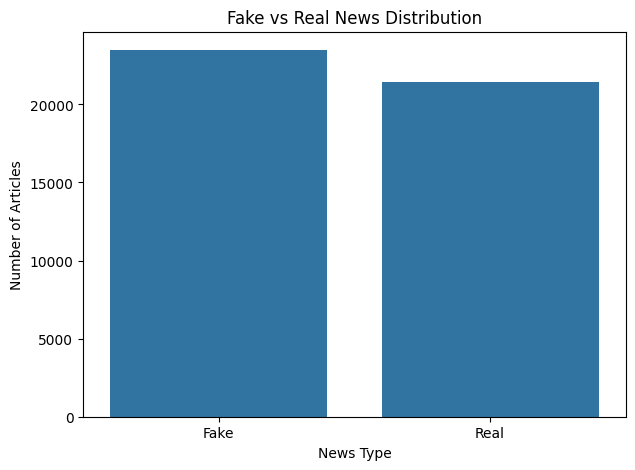


            SUBJECT ANALYSIS
subject
politicsNews       11272
worldnews          10145
News                9050
politics            6841
left-news           4459
Government News     1570
US_News              783
Middle-east          778
Name: count, dtype: int64


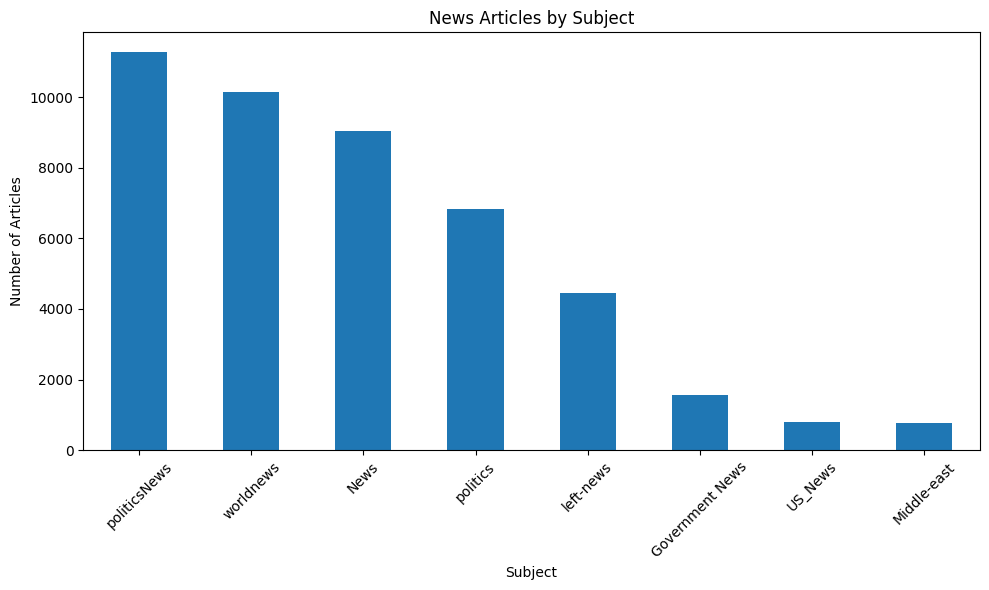


           ARTICLE LENGTH
count    44898.000000
mean      2469.109693
std       2171.617091
min          1.000000
25%       1234.000000
50%       2186.000000
75%       3105.000000
max      51794.000000
Name: text_length, dtype: float64


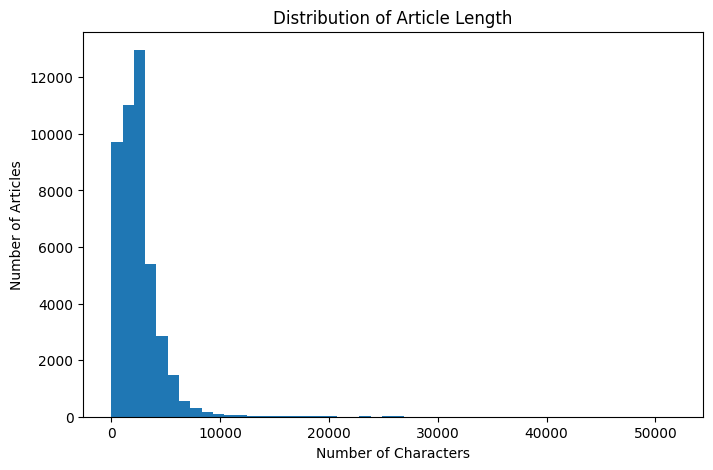

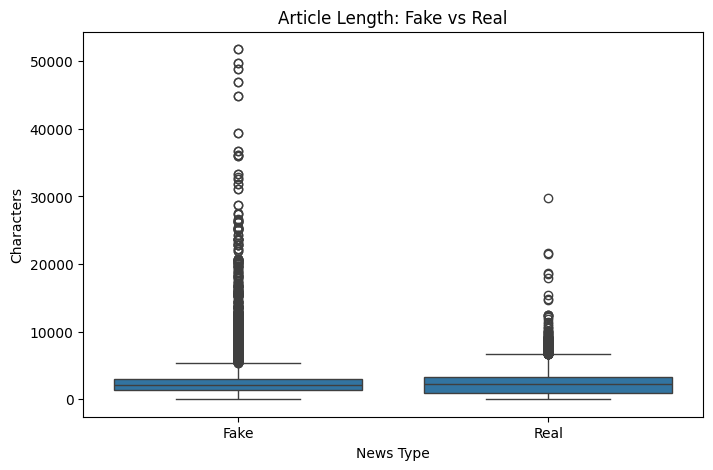


        AVERAGE ARTICLE LENGTH
Fake: 2547.4
Real: 2383.28

             COMMON WORDS

Top 20 Words:
[('s', 282576), ('trump', 134000), ('said', 132825), ('who', 70082), ('president', 55892), ('u', 54290), ('t', 54188), ('had', 46138), ('been', 42641), ('people', 41857), ('were', 40535), ('more', 40017), ('one', 37927), ('after', 37205), ('if', 35790), ('all', 35077), ('out', 34675), ('state', 34488), ('what', 33654), ('when', 32677)]


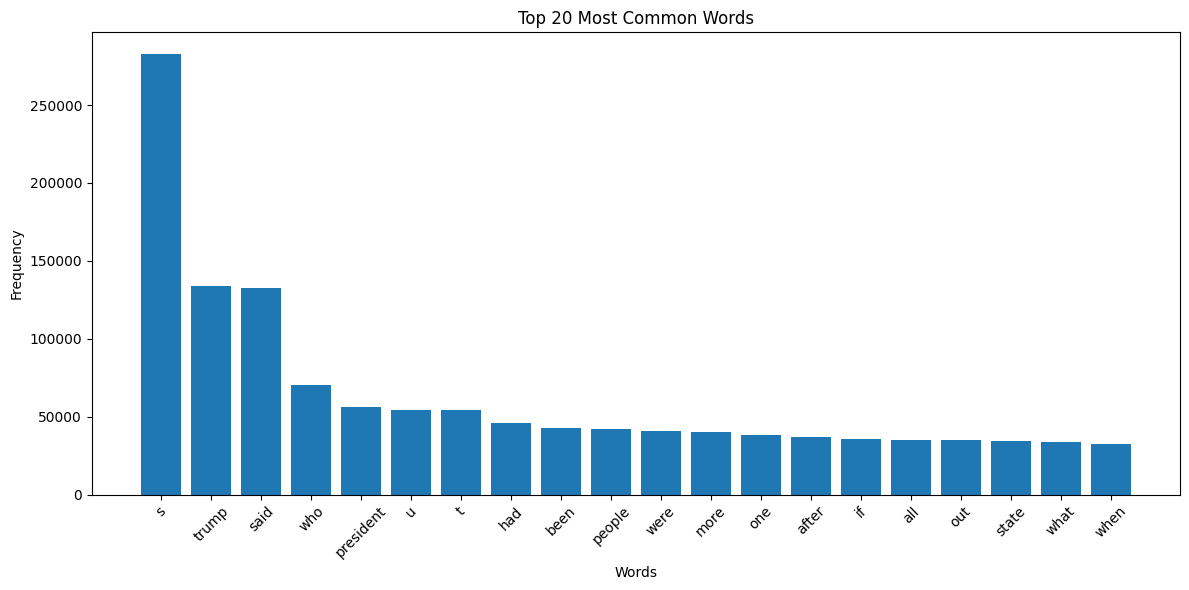


             DATA CLEANING
Before duplicates removal: 44898
After duplicates removal: 38646
Duplicates removed: 6252

             AFTER SAMPLING
Total samples: 15458
Fake samples: 6961
Real samples: 8497

          INPUT AND OUTPUT
X = Article Text
y = Label
0 = Fake
1 = Real

           TRAIN TEST SPLIT
Training: 9274
Testing: 6184

       LOADING SEMANTIC MODEL


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (8 outputs left out)

Sentence Transformer loaded.

        CREATING EMBEDDINGS


Batches:   0%|          | 0/290 [00:00<?, ?it/s]

Batches:   0%|          | 0/194 [00:00<?, ?it/s]


Training embedding shape: (9274, 384)
Testing embedding shape: (6184, 384)

        TRAINING CLASSIFIER
Training completed.

            MODEL RESULTS
Accuracy : 95.6 %
Precision: 95.6 %
Recall   : 95.6 %
F1-Score : 95.6 %

          CONFUSION MATRIX
[[2630  155]
 [ 117 3282]]

True Negative  (TN): 2630
False Positive (FP): 155
False Negative (FN): 117
True Positive  (TP): 3282


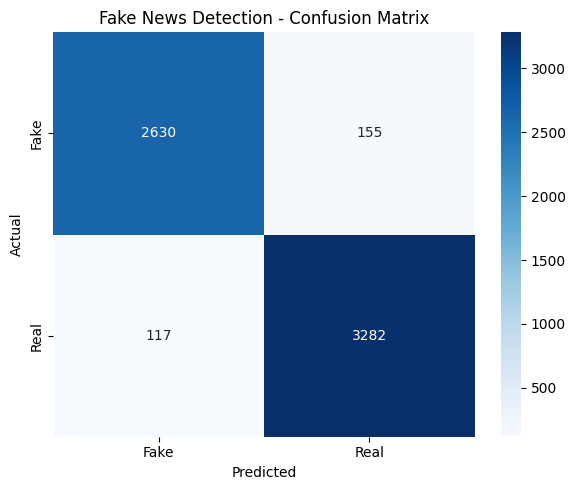


         CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fake       0.96      0.94      0.95      2785
        Real       0.95      0.97      0.96      3399

    accuracy                           0.96      6184
   macro avg       0.96      0.95      0.96      6184
weighted avg       0.96      0.96      0.96      6184


          TEST NEW NEWS

Input:
The government announced a new economic policy today.

Prediction: REAL NEWS
Fake Probability: 7.12 %
Real Probability: 92.88 %


In [ ]:
# ============================================================
# FAKE NEWS DETECTION
# Kaggle Dataset + EDA + Semantic NLP
# Sentence Transformer + Logistic Regression
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
import re

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sentence_transformers import SentenceTransformer


# ============================================================
# 2. DOWNLOAD KAGGLE DATASET
# ============================================================

path = kagglehub.dataset_download(
    "clmentbisaillon/fake-and-real-news-dataset"
)

print("Path to dataset files:", path)


# ============================================================
# 3. LOAD FAKE AND REAL DATASETS
# ============================================================

fake = pd.read_csv(
    f"{path}/Fake.csv"
)

true = pd.read_csv(
    f"{path}/True.csv"
)


# ============================================================
# 4. BASIC DATASET INFORMATION
# ============================================================

print("\n==========================================")
print("          DATASET INFORMATION")
print("==========================================")

print("\nFake News Articles:", len(fake))
print("Real News Articles:", len(true))
print("Total Articles:", len(fake) + len(true))

print("\nFake Dataset Shape:", fake.shape)
print("Real Dataset Shape:", true.shape)


# ============================================================
# 5. COLUMN INFORMATION
# ============================================================

print("\n==========================================")
print("             COLUMN NAMES")
print("==========================================")

print("\nFake Columns:")
print(fake.columns.tolist())

print("\nReal Columns:")
print(true.columns.tolist())


# ============================================================
# 6. FIRST 5 ROWS
# ============================================================

print("\n==========================================")
print("             SAMPLE DATA")
print("==========================================")

print("\nFake News:")
print(fake.head())

print("\nReal News:")
print(true.head())


# ============================================================
# 7. DATA TYPES
# ============================================================

print("\n==========================================")
print("              DATA TYPES")
print("==========================================")

print("\nFake Dataset:")
print(fake.dtypes)

print("\nReal Dataset:")
print(true.dtypes)


# ============================================================
# 8. MISSING VALUES
# ============================================================

print("\n==========================================")
print("            MISSING VALUES")
print("==========================================")

print("\nFake Dataset:")
print(fake.isnull().sum())

print("\nReal Dataset:")
print(true.isnull().sum())


# ============================================================
# 9. DUPLICATE VALUES
# ============================================================

print("\n==========================================")
print("              DUPLICATES")
print("==========================================")

print(
    "Fake duplicates:",
    fake.duplicated().sum()
)

print(
    "Real duplicates:",
    true.duplicated().sum()
)


# ============================================================
# 10. ADD LABELS
# ============================================================

# 0 = Fake
# 1 = Real

fake["label"] = 0
true["label"] = 1


# ============================================================
# 11. COMBINE DATASETS
# ============================================================

data = pd.concat(
    [fake, true],
    axis=0
).reset_index(drop=True)


print("\n==========================================")
print("         COMBINED DATASET")
print("==========================================")

print("\nShape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())


# ============================================================
# 12. CLASS DISTRIBUTION
# ============================================================

fake_count = (
    data["label"] == 0
).sum()

real_count = (
    data["label"] == 1
).sum()

print("\n==========================================")
print("          CLASS DISTRIBUTION")
print("==========================================")

print("Fake:", fake_count)
print("Real:", real_count)
print("Total:", len(data))

print(
    "\nFake Percentage:",
    round(fake_count / len(data) * 100, 2),
    "%"
)

print(
    "Real Percentage:",
    round(real_count / len(data) * 100, 2),
    "%"
)


# ============================================================
# 13. FAKE VS REAL GRAPH
# ============================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    x="label",
    data=data
)

plt.xticks(
    [0, 1],
    ["Fake", "Real"]
)

plt.title(
    "Fake vs Real News Distribution"
)

plt.xlabel("News Type")
plt.ylabel("Number of Articles")

plt.show()


# ============================================================
# 14. SUBJECT ANALYSIS
# ============================================================

print("\n==========================================")
print("            SUBJECT ANALYSIS")
print("==========================================")

print(
    data["subject"].value_counts()
)


# ============================================================
# 15. SUBJECT GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

data["subject"].value_counts().plot(
    kind="bar"
)

plt.title(
    "News Articles by Subject"
)

plt.xlabel("Subject")
plt.ylabel("Number of Articles")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# ============================================================
# 16. ARTICLE LENGTH
# ============================================================

data["text_length"] = (
    data["text"]
    .astype(str)
    .str.len()
)

print("\n==========================================")
print("           ARTICLE LENGTH")
print("==========================================")

print(
    data["text_length"].describe()
)


# ============================================================
# 17. ARTICLE LENGTH DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    data["text_length"],
    bins=50
)

plt.title(
    "Distribution of Article Length"
)

plt.xlabel(
    "Number of Characters"
)

plt.ylabel(
    "Number of Articles"
)

plt.show()


# ============================================================
# 18. FAKE VS REAL ARTICLE LENGTH
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    x="label",
    y="text_length",
    data=data
)

plt.xticks(
    [0, 1],
    ["Fake", "Real"]
)

plt.title(
    "Article Length: Fake vs Real"
)

plt.xlabel("News Type")
plt.ylabel("Characters")

plt.show()


# ============================================================
# 19. AVERAGE ARTICLE LENGTH
# ============================================================

print("\n==========================================")
print("        AVERAGE ARTICLE LENGTH")
print("==========================================")

print(
    "Fake:",
    round(
        data[data["label"] == 0]["text_length"].mean(),
        2
    )
)

print(
    "Real:",
    round(
        data[data["label"] == 1]["text_length"].mean(),
        2
    )
)


# ============================================================
# 20. COMMON WORD ANALYSIS
# ============================================================

print("\n==========================================")
print("             COMMON WORDS")
print("==========================================")

all_text = " ".join(
    data["text"].astype(str)
)

words = re.findall(
    r"\b[a-zA-Z]+\b",
    all_text.lower()
)


# Basic stop words

stop_words = {
    "the", "and", "is", "in", "to", "of",
    "a", "for", "on", "that", "with",
    "as", "was", "at", "by", "an",
    "be", "this", "from", "it", "or",
    "are", "has", "have", "but", "not",
    "they", "their", "will", "would",
    "about", "which", "he", "she",
    "his", "her", "we", "you", "i"
}

filtered_words = [
    word
    for word in words
    if word not in stop_words
]

word_counts = Counter(
    filtered_words
)

print(
    "\nTop 20 Words:"
)

print(
    word_counts.most_common(20)
)


# ============================================================
# 21. COMMON WORD GRAPH
# ============================================================

top_words = word_counts.most_common(20)

word_names = [
    x[0]
    for x in top_words
]

word_frequency = [
    x[1]
    for x in top_words
]

plt.figure(figsize=(12, 6))

plt.bar(
    word_names,
    word_frequency
)

plt.title(
    "Top 20 Most Common Words"
)

plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# ============================================================
# 22. REMOVE MISSING TEXT
# ============================================================

data = data.dropna(
    subset=["text"]
).reset_index(drop=True)


# ============================================================
# 23. REMOVE DUPLICATE ARTICLES
# ============================================================

before = len(data)

data = data.drop_duplicates(
    subset=["text"]
).reset_index(drop=True)

after = len(data)

print("\n==========================================")
print("             DATA CLEANING")
print("==========================================")

print("Before duplicates removal:", before)
print("After duplicates removal:", after)
print("Duplicates removed:", before - after)


# ============================================================
# 24. TAKE DATA SAMPLE
# ============================================================

# Your original code used 5%.
# Here we use 40% because it gives the model
# more training examples.

data = data.sample(
    frac=0.40,
    random_state=42
).reset_index(drop=True)


# Shuffle

data = data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)


print("\n==========================================")
print("             AFTER SAMPLING")
print("==========================================")

print(
    "Total samples:",
    len(data)
)

print(
    "Fake samples:",
    (data["label"] == 0).sum()
)

print(
    "Real samples:",
    (data["label"] == 1).sum()
)


# ============================================================
# 25. INPUT AND OUTPUT
# ============================================================

X = data["text"]
y = data["label"]


print("\n==========================================")
print("          INPUT AND OUTPUT")
print("==========================================")

print("X = Article Text")
print("y = Label")
print("0 = Fake")
print("1 = Real")


# ============================================================
# 26. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)


print("\n==========================================")
print("           TRAIN TEST SPLIT")
print("==========================================")

print(
    "Training:",
    len(X_train)
)

print(
    "Testing:",
    len(X_test)
)


# ============================================================
# 27. LOAD SENTENCE TRANSFORMER
# ============================================================

print("\n==========================================")
print("       LOADING SEMANTIC MODEL")
print("==========================================")

embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print(
    "Sentence Transformer loaded."
)


# ============================================================
# 28. CREATE SEMANTIC EMBEDDINGS
# ============================================================

print("\n==========================================")
print("        CREATING EMBEDDINGS")
print("==========================================")

X_train_embeddings = embedding_model.encode(
    X_train.tolist(),
    batch_size=32,
    show_progress_bar=True
)

X_test_embeddings = embedding_model.encode(
    X_test.tolist(),
    batch_size=32,
    show_progress_bar=True
)


print(
    "\nTraining embedding shape:",
    X_train_embeddings.shape
)

print(
    "Testing embedding shape:",
    X_test_embeddings.shape
)


# ============================================================
# 29. TRAIN CLASSIFIER
# ============================================================

print("\n==========================================")
print("        TRAINING CLASSIFIER")
print("==========================================")

model = LogisticRegression(
    max_iter=1000
)

model.fit(
    X_train_embeddings,
    y_train
)

print(
    "Training completed."
)


# ============================================================
# 30. PREDICTION
# ============================================================

y_pred = model.predict(
    X_test_embeddings
)


# ============================================================
# 31. METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)


# ============================================================
# 32. RESULTS
# ============================================================

print("\n==========================================")
print("            MODEL RESULTS")
print("==========================================")

print(
    "Accuracy :",
    round(accuracy * 100, 2),
    "%"
)

print(
    "Precision:",
    round(precision * 100, 2),
    "%"
)

print(
    "Recall   :",
    round(recall * 100, 2),
    "%"
)

print(
    "F1-Score :",
    round(f1 * 100, 2),
    "%"
)


# ============================================================
# 33. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)


print("\n==========================================")
print("          CONFUSION MATRIX")
print("==========================================")

print(cm)


# ============================================================
# 34. TP TN FP FN
# ============================================================

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative  (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive  (TP):", tp)


# ============================================================
# 35. CONFUSION MATRIX GRAPH
# ============================================================

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Fake News Detection - Confusion Matrix"
)

plt.tight_layout()

plt.show()


# ============================================================
# 36. CLASSIFICATION REPORT
# ============================================================

print("\n==========================================")
print("         CLASSIFICATION REPORT")
print("==========================================")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Fake",
            "Real"
        ]
    )
)


# ============================================================
# 37. TEST NEW HEADLINE / ARTICLE
# ============================================================

print("\n==========================================")
print("          TEST NEW NEWS")
print("==========================================")


new_article = [
    "The government announced a new economic policy today."
]


# Convert to semantic embedding

new_embedding = embedding_model.encode(
    new_article
)


# Predict

prediction = model.predict(
    new_embedding
)


# Probability

probability = model.predict_proba(
    new_embedding
)


print("\nInput:")
print(new_article[0])


if prediction[0] == 0:

    print("\nPrediction: FAKE NEWS")

else:

    print("\nPrediction: REAL NEWS")


print(
    "Fake Probability:",
    round(probability[0][0] * 100, 2),
    "%"
)

print(
    "Real Probability:",
    round(probability[0][1] * 100, 2),
    "%"
)